# Статистический анализ эффективности программы лояльности и её влияния на финансовые показатели компании (розничная торговля)

**Описание проекта**

Исследование проводится в интересах торговой сети продуктовых магазинов «Соседушка», где около 55% покупок совершают клиенты с картами лояльности. Руководством компании поставлена задача провести комплексный анализ текущей программы лояльности и оценить ее эффективность.

**Наша задача** - провести анализ поведения клиентов (размер чека, объем корзины и маржинальность).

**Результаты исследования** позволят компании оптимизировать затраты на целевой маркетинг и пересмотреть программу лояльности так, чтобы она увеличивала чистую прибыль.

**Описание данных**

Данные о продажах получим из файла `Соседушка_данные.xlsx` со следующими вкладками:

    `fact_sales` - Таблица фактов — все продажи сети за 2024–2025 годы
    `dim_products` - Справочник товаров: наименование, бренд, категория, подкатегория, цены, поставщик

**Ход исследования**

Исследование пройдет в три этапа:
1. Изучение и обработка данных:
- Заполнение пропусков
- Кодирование данных
- Добавление новых столбцов и формирование новых таблиц
2. Исследовательский анализ данных:
- Изучение медианы, моды, средних значений и стандартных отклонений
- Построение графиков распределения признаков и boxplot для клиентов без карт лояльности и с картами лояльности
3. Проверка гипотез:
- Гипотеза 1. Средние суммы чеков между клиентами с картами лояльности и без карт различаются
- Гипотеза 2. Распределения сумм чеков между клиентами с картами лояльности и без карт различаются
- Гипотеза 3. Средняя маржа чеков между клиентами с картами лояльности и без карт различаются
- Гипотеза 4. Изначальная маржинальность чеков (до применения скидок) у клиентов с картами лояльности и без карт различается
- Гипотеза 5. Существует взаимосвязь между категорией приобретаемого товара и размером предоставляемой по карте скидки (5%, 10%, 15%)
- Гипотеза 6. Количество товаров в чеке (размер корзины) у клиентов с картами лояльности и без карт различается

## Изучение и обработка данных

In [1]:
# Импортируем необходимые библиотеки
import pandas as pd
import numpy as np
from scipy.stats import *
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Настроим отображение данных
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', '{:.2f}'.format)

In [3]:
# Считываем данные
excel_file = 'Соседушка_данные.xlsx'
sales = pd.read_excel(excel_file, sheet_name='fact_sales')
products = pd.read_excel(excel_file, sheet_name='dim_products')

In [4]:
# Сформируем одну большую таблицу с необходимыми данными
df = sales.merge(products[['id_товара', 'категория', 'цена_закупки_руб']], on='id_товара', how='left')

In [5]:
# Дополним таблицу столбцами, которые потребуются для проведения расчетов
df['маржа_со_скидкой_руб'] = df['сумма_строки'] - (df['цена_закупки_руб'] * df['количество'])
df['сумма_строки_без_скидки'] = df['количество'] * df['цена_за_единицу']
df['маржа_без_скидки_руб'] = (df['цена_за_единицу'] - df['цена_закупки_руб']) * df['количество']

In [6]:
def get_info(data):
    print('------ Первые 5 строк ------')
    display(data.head())
    print()
    print('------ Типы данных ------')
    data.info()
    print()
    print('------ Уникальные значения в файле ------')
    display(data.nunique())
    print()
    print('------ Пропуски в файле ------')
    display(data.isna().sum())
    print()
    print('------ Дубликаты в файле ------')
    display(data.duplicated().sum())

In [7]:
get_info(df)

------ Первые 5 строк ------


,id_чека,дата_время,id_магазина,id_товара,id_клиента,количество,цена_за_единицу,скидка_процент,сумма_строки,способ_оплаты,категория,цена_закупки_руб,маржа_со_скидкой_руб,сумма_строки_без_скидки,маржа_без_скидки_руб
0,1000001,2024-01-01 20:32:00,1,89,864.00,3,326.18,10,880.69,карта,Снеки,236.23,172.00,978.54,269.85
1,1000001,2024-01-01 20:32:00,1,99,864.00,1,187.24,0,187.24,карта,Детское питание,132.04,55.20,187.24,55.20
2,1000001,2024-01-01 20:32:00,1,49,864.00,1,95.26,0,95.26,карта,Сладости,67.56,27.70,95.26,27.70
3,1000001,2024-01-01 20:32:00,1,48,864.00,1,273.40,0,273.40,карта,Сладости,178.58,94.82,273.40,94.82
4,1000001,2024-01-01 20:32:00,1,21,864.00,1,127.58,0,127.58,карта,Овощи и фрукты,97.33,30.25,127.58,30.25



------ Типы данных ------
<class 'pandas.DataFrame'>
RangeIndex: 81238 entries, 0 to 81237
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   id_чека                  81238 non-null  int64         
 1   дата_время               81238 non-null  datetime64[us]
 2   id_магазина              81238 non-null  int64         
 3   id_товара                81238 non-null  int64         
 4   id_клиента               44744 non-null  float64       
 5   количество               81238 non-null  int64         
 6   цена_за_единицу          81238 non-null  float64       
 7   скидка_процент           81238 non-null  int64         
 8   сумма_строки             81238 non-null  float64       
 9   способ_оплаты            81238 non-null  str           
 10  категория                81238 non-null  str           
 11  цена_закупки_руб         81238 non-null  float64       
 12  маржа_со_скидкой

id_чека                    22790
дата_время                 22286
id_магазина                   20
id_товара                    101
id_клиента                  4561
количество                     3
цена_за_единицу            30690
скидка_процент                 4
сумма_строки               38606
способ_оплаты                  3
категория                     14
цена_закупки_руб             101
маржа_со_скидкой_руб       34750
сумма_строки_без_скидки    36957
маржа_без_скидки_руб       33724
dtype: int64


------ Пропуски в файле ------


id_чека                        0
дата_время                     0
id_магазина                    0
id_товара                      0
id_клиента                 36494
количество                     0
цена_за_единицу                0
скидка_процент                 0
сумма_строки                   0
способ_оплаты                  0
категория                      0
цена_закупки_руб               0
маржа_со_скидкой_руб           0
сумма_строки_без_скидки        0
маржа_без_скидки_руб           0
dtype: int64


------ Дубликаты в файле ------


np.int64(0)

**Выводы:**
- дубликаты отсутствуют;
 - в одном чеке несколько строк-позиций, поэтому значения столбцов повторяются. Сформируем еще одну таблицу `df_agg` сгруппированную по `id_чека`;
- в столбцах `id_клиента` указаны уникальные номера карт лояльности клиентов и имеются пропуски по тем клиентам, у которых отсутствуют карты лояльности. Для дальнейшего анализа разделим покупателей на две категории: 1 - с картами лояльности, 0 - без карт;
- переименуем столбцы `id_клиента`, `количество`, `сумма_строки`, `категория` для уточнения контекста данных.

In [8]:
# Преобразуем столбец id_клиента, а также переименуем столбцы
df['id_клиента'] = (~df['id_клиента'].isna()).astype(int)
df = df.rename(columns={'id_клиента': 'карта_лояльности'})
df = df.rename(columns={'количество': 'количество_товара'})
df = df.rename(columns={'сумма_строки': 'сумма_строки_со_скидкой'})
df = df.rename(columns={'категория': 'категория_товара'})

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 81238 entries, 0 to 81237
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   id_чека                  81238 non-null  int64         
 1   дата_время               81238 non-null  datetime64[us]
 2   id_магазина              81238 non-null  int64         
 3   id_товара                81238 non-null  int64         
 4   карта_лояльности         81238 non-null  int64         
 5   количество_товара        81238 non-null  int64         
 6   цена_за_единицу          81238 non-null  float64       
 7   скидка_процент           81238 non-null  int64         
 8   сумма_строки_со_скидкой  81238 non-null  float64       
 9   способ_оплаты            81238 non-null  str           
 10  категория_товара         81238 non-null  str           
 11  цена_закупки_руб         81238 non-null  float64       
 12  маржа_со_скидкой_руб     81238 non-null  fl

In [10]:
# выведем названия всех столбцов
df.columns

Index(['id_чека', 'дата_время', 'id_магазина', 'id_товара', 'карта_лояльности',
       'количество_товара', 'цена_за_единицу', 'скидка_процент',
       'сумма_строки_со_скидкой', 'способ_оплаты', 'категория_товара',
       'цена_закупки_руб', 'маржа_со_скидкой_руб', 'сумма_строки_без_скидки',
       'маржа_без_скидки_руб'],
      dtype='str')

In [11]:
# создадим словарь и сгруппируем данные по id_чека
max_cols = ['дата_время', 'id_магазина', 'карта_лояльности', 'способ_оплаты']
sum_cols = ['количество_товара', 'сумма_строки_со_скидкой', 'маржа_со_скидкой_руб', 'сумма_строки_без_скидки', 'маржа_без_скидки_руб']

agg_dict = {
    **{col: 'max' for col in max_cols},
    **{col: 'sum' for col in sum_cols}
}

df_agg = df.groupby('id_чека').agg(agg_dict).reset_index()

# посчитаем базовую маржу в % в разрезе чеков
df_agg['маржа_чека_без_скидки_проц'] = df_agg['маржа_без_скидки_руб'] / df_agg['сумма_строки_без_скидки'] * 100

In [12]:
# Посмотрим на датасет
get_info(df_agg)

------ Первые 5 строк ------


,id_чека,дата_время,id_магазина,карта_лояльности,способ_оплаты,количество_товара,сумма_строки_со_скидкой,маржа_со_скидкой_руб,сумма_строки_без_скидки,маржа_без_скидки_руб,маржа_чека_без_скидки_проц
0,1000001,2024-01-01 20:32:00,1,1,карта,7,1564.17,379.97,1662.02,477.82,28.75
1,1000002,2024-01-01 15:22:00,2,0,СБП,4,1153.28,393.93,1153.28,393.93,34.16
2,1000003,2024-01-01 12:57:00,2,0,карта,2,632.03,147.28,632.03,147.28,23.30
3,1000004,2024-01-01 18:22:00,3,1,карта,7,967.26,270.85,996.19,299.78,30.09
4,1000005,2024-01-01 16:24:00,3,0,карта,3,783.90,202.95,783.90,202.95,25.89



------ Типы данных ------
<class 'pandas.DataFrame'>
RangeIndex: 22790 entries, 0 to 22789
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   id_чека                     22790 non-null  int64         
 1   дата_время                  22790 non-null  datetime64[us]
 2   id_магазина                 22790 non-null  int64         
 3   карта_лояльности            22790 non-null  int64         
 4   способ_оплаты               22790 non-null  str           
 5   количество_товара           22790 non-null  int64         
 6   сумма_строки_со_скидкой     22790 non-null  float64       
 7   маржа_со_скидкой_руб        22790 non-null  float64       
 8   сумма_строки_без_скидки     22790 non-null  float64       
 9   маржа_без_скидки_руб        22790 non-null  float64       
 10  маржа_чека_без_скидки_проц  22790 non-null  float64       
dtypes: datetime64[us](1), float64(5), int6

id_чека                       22790
дата_время                    22286
id_магазина                      20
карта_лояльности                  2
способ_оплаты                     3
количество_товара                22
сумма_строки_со_скидкой       21633
маржа_со_скидкой_руб          21168
сумма_строки_без_скидки       21563
маржа_без_скидки_руб          21192
маржа_чека_без_скидки_проц    22568
dtype: int64


------ Пропуски в файле ------


id_чека                       0
дата_время                    0
id_магазина                   0
карта_лояльности              0
способ_оплаты                 0
количество_товара             0
сумма_строки_со_скидкой       0
маржа_со_скидкой_руб          0
сумма_строки_без_скидки       0
маржа_без_скидки_руб          0
маржа_чека_без_скидки_проц    0
dtype: int64


------ Дубликаты в файле ------


np.int64(0)

## Исследовательский анализ данных

### Изучение медианы, моды, средних значений и стандартных отклонений

In [13]:
# Посмотрим на полученные таблицы
df.describe().T

,count,mean,min,25%,50%,75%,max,std
id_чека,81238.00,1011470.01,1000001.00,1005765.00,1011531.00,1017185.00,1022790.00,6582.40
дата_время,81238,2025-01-09 09:29:59.608557,2024-01-01 09:42:00,2024-07-12 12:45:45,2025-01-17 11:06:00,2025-07-09 19:43:00,2025-12-31 22:40:00,NaN
id_магазина,81238.00,10.03,1.00,6.00,10.00,16.00,20.00,5.93
id_товара,81238.00,59.77,1.00,35.00,64.00,88.00,101.00,29.78
карта_лояльности,81238.00,0.55,0.00,0.00,1.00,1.00,1.00,0.50
количество_товара,81238.00,1.30,1.00,1.00,1.00,1.00,3.00,0.56
цена_за_единицу,81238.00,211.59,37.84,81.81,137.51,266.47,782.15,174.79
скидка_процент,81238.00,1.96,0.00,0.00,0.00,0.00,15.00,4.37
сумма_строки_со_скидкой,81238.00,269.45,32.27,102.15,175.94,337.00,2345.04,269.13
цена_закупки_руб,81238.00,152.85,25.98,61.19,98.10,193.65,622.73,130.75


In [14]:
df_agg.describe().T

,count,mean,min,25%,50%,75%,max,std
id_чека,22790.00,1011395.50,1000001.00,1005698.25,1011395.50,1017092.75,1022790.00,6579.05
дата_время,22790,2025-01-07 00:01:50.903905,2024-01-01 09:42:00,2024-07-09 19:03:00,2025-01-12 12:55:00,2025-07-06 16:45:45,2025-12-31 22:40:00,NaN
id_магазина,22790.00,10.42,1.00,5.00,10.00,15.00,20.00,5.77
карта_лояльности,22790.00,0.55,0.00,0.00,1.00,1.00,1.00,0.50
количество_товара,22790.00,4.63,1.00,2.00,4.00,6.00,22.00,3.33
сумма_строки_со_скидкой,22790.00,960.49,33.48,329.96,731.75,1351.54,6947.38,829.12
маржа_со_скидкой_руб,22790.00,252.73,1.06,86.85,191.81,354.68,1895.69,219.99
сумма_строки_без_скидки,22790.00,979.52,37.86,336.41,747.04,1380.55,7097.56,844.69
маржа_без_скидки_руб,22790.00,271.76,5.87,96.11,208.83,381.19,1895.69,232.96
маржа_чека_без_скидки_проц,22790.00,28.22,13.42,25.44,28.27,30.95,41.71,4.34


In [15]:
df.mode().T[0]

id_чека                                1000008
дата_время                 2024-11-06 19:47:00
id_магазина                              11.00
id_товара                                96.00
карта_лояльности                          1.00
количество_товара                         1.00
цена_за_единицу                          70.85
скидка_процент                            0.00
сумма_строки_со_скидкой                  72.45
способ_оплаты                            карта
категория_товара                       Напитки
цена_закупки_руб                        117.69
маржа_со_скидкой_руб                     19.20
сумма_строки_без_скидки                  70.03
маржа_без_скидки_руб                     11.93
Name: 0, dtype: object

In [16]:
df_agg.mode().T[0]

id_чека                                   1000001
дата_время                    2024-04-25 18:04:00
id_магазина                                 11.00
карта_лояльности                             1.00
способ_оплаты                               карта
количество_товара                            1.00
сумма_строки_со_скидкой                     53.29
маржа_со_скидкой_руб                        73.93
сумма_строки_без_скидки                     53.29
маржа_без_скидки_руб                        84.84
маржа_чека_без_скидки_проц                  20.11
Name: 0, dtype: object

**Выводы:**
- всего имеется 81238 позиций покупок, из них 44744 произведены клиентами с картами лояльности (55%);
- всего имеется 22790 чеков, из них 12521 произведены клиентами с картами лояльности (55%);
- средняя сумма чеков со скидкой - 960.49 руб., медиана - 731,75 руб., стандартное отклонение - 829.12 руб. (данные сильно разбросаны);
- средняя сумма чеков без скидки - 979.52 руб., медиана - 747.04 руб., стандартное отклонение - 844.69 руб. (данные сильно разбросаны);
- средняя маржа чеков со скидкой - 252.73 руб., медиана - 191,81 руб., стандартное отклонение - 219.99 руб. (данные сильно разбросаны);
- средняя маржа чеков без скидки - 271.76 руб., медиана - 208.83 руб., стандартное отклонение - 232.96 руб. (данные сильно разбросаны);
- количество товаров в одном чеке в диапазоне от 1 до 22, в среднем - 4,63, чаще всего - 1 ед.

In [17]:
#Разделим выборки на клиентов с картами лояльности и без
with_card = df_agg[df_agg['карта_лояльности'] == 1]
no_card = df_agg[df_agg['карта_лояльности'] == 0]

In [18]:
def print_basic_statistics(data):
    print('Размер выборки:', len(data))
    print('Выборочное среднее:', data.mean())
    print('Выборочная медиана:', data.median())
    print('Выборочное среднеквадратическое отклонение:', data.std())
    print('Выборочный коэффициент асиметрии:', data.skew())

In [19]:
print_basic_statistics(with_card['сумма_строки_со_скидкой'])

Размер выборки: 12521
Выборочное среднее: 947.8474506828528
Выборочная медиана: 721.24
Выборочное среднеквадратическое отклонение: 819.2611727213368
Выборочный коэффициент асиметрии: 1.5415255597441582


In [20]:
print_basic_statistics(no_card['сумма_строки_со_скидкой'])

Размер выборки: 10269
Выборочное среднее: 975.9083065537054
Выборочная медиана: 745.78
Выборочное среднеквадратическое отклонение: 840.7755839890824
Выборочный коэффициент асиметрии: 1.4531209621677121


In [21]:
print_basic_statistics(with_card['маржа_со_скидкой_руб'])

Размер выборки: 12521
Выборочное среднее: 237.90699544764797
Выборочная медиана: 181.21000000000004
Выборочное среднеквадратическое отклонение: 207.43275344402898
Выборочный коэффициент асиметрии: 1.5701761986091776


In [22]:
print_basic_statistics(no_card['маржа_со_скидкой_руб'])

Размер выборки: 10269
Выборочное среднее: 270.81181225046254
Выборочная медиана: 207.25999999999996
Выборочное среднеквадратическое отклонение: 233.12855957287803
Выборочный коэффициент асиметрии: 1.5147185119754918


**Выводы:**

Показатели суммы и маржи чеков покупателей без карт выше, чем у клиентов с картами лояльности;

### Построение графиков распределения признаков и boxplot для клиентов без карт лояльности и с картами лояльности

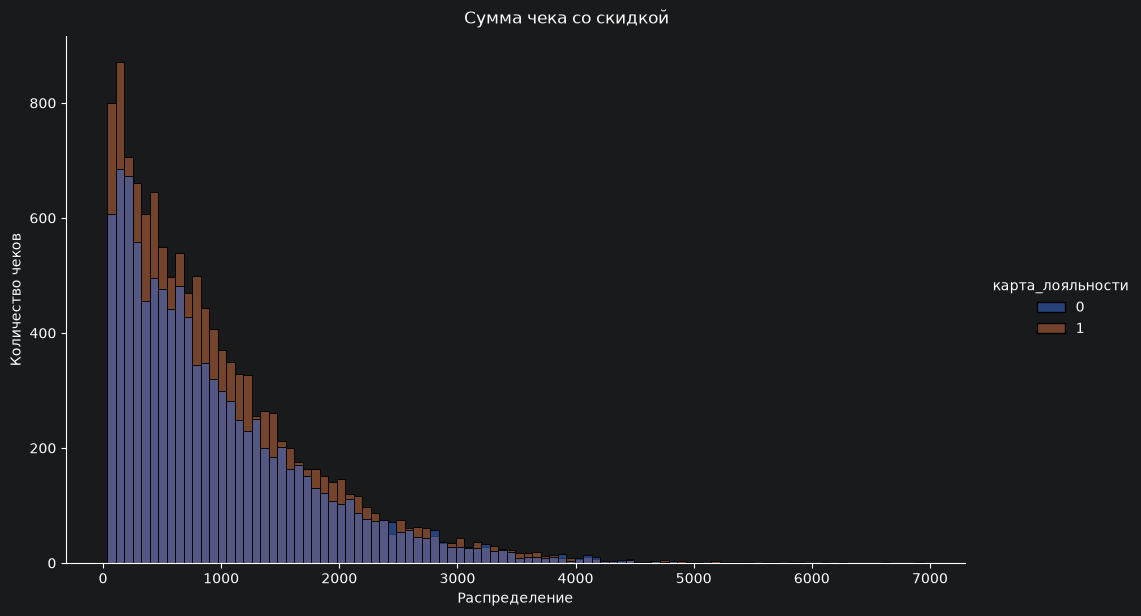

In [23]:
# Посмотрим на распределение выборок
g = sns.displot(df, x=df_agg['сумма_строки_со_скидкой'], hue='карта_лояльности', kind='hist', height=6, aspect=1.66)
g.set_axis_labels('Распределение', 'Количество чеков')
g.figure.suptitle('Сумма чека со скидкой', y=1.02)
plt.show()

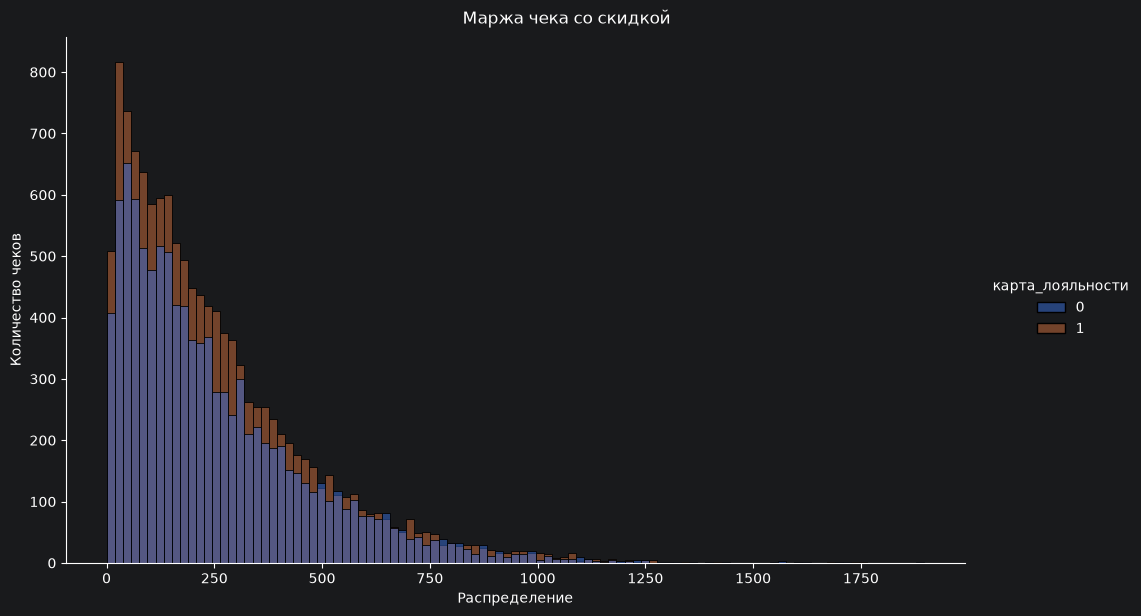

In [24]:
# Посмотрим на распределение выборок
g = sns.displot(df, x=df_agg['маржа_со_скидкой_руб'], hue='карта_лояльности', kind='hist', height=6, aspect=1.66)
g.set_axis_labels('Распределение', 'Количество чеков')
g.figure.suptitle('Маржа чека со скидкой', y=1.02)
plt.show()

**Выводы:**
- данные в обеих выборках распределены ассиметрично со смещением вправо;
- форма распределения у обеих групп практически идентична, что может говорить об одинаковом поведении клиентов: чаще покупают на небольшие суммы и редко совершают крупные покупки. Скидки не сильно сдвигают пик трат клиентов вправо.
- большинство сумм чеков концентрируется в диапазоне от 0 до 1500 руб., а маржи - от 0 до 400 руб.;
- после 4000 руб. график сумм чеков практически сливается с нулем, с единичными чеками до 7000+ руб.;
- после 1000 руб. графим маржи чеков так же практически сливается с нулем, с единичными чеками до 1750+ руб.

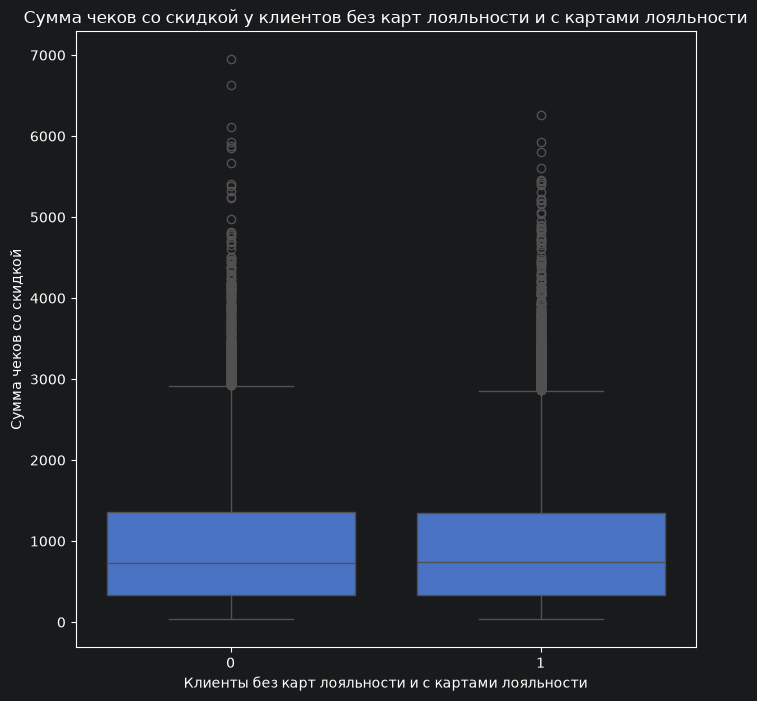

In [25]:
# посмотрим графики boxplot
plt.figure(figsize=(8, 8))
(sns.boxplot(x = 'карта_лояльности', y = df_agg['сумма_строки_со_скидкой'], data = df)
    .set(title = 'Сумма чеков со скидкой у клиентов без карт лояльности и с картами лояльности', xlabel = 'Клиенты без карт лояльности и с картами лояльности',
         ylabel = 'Сумма чеков со скидкой'))
plt.show()

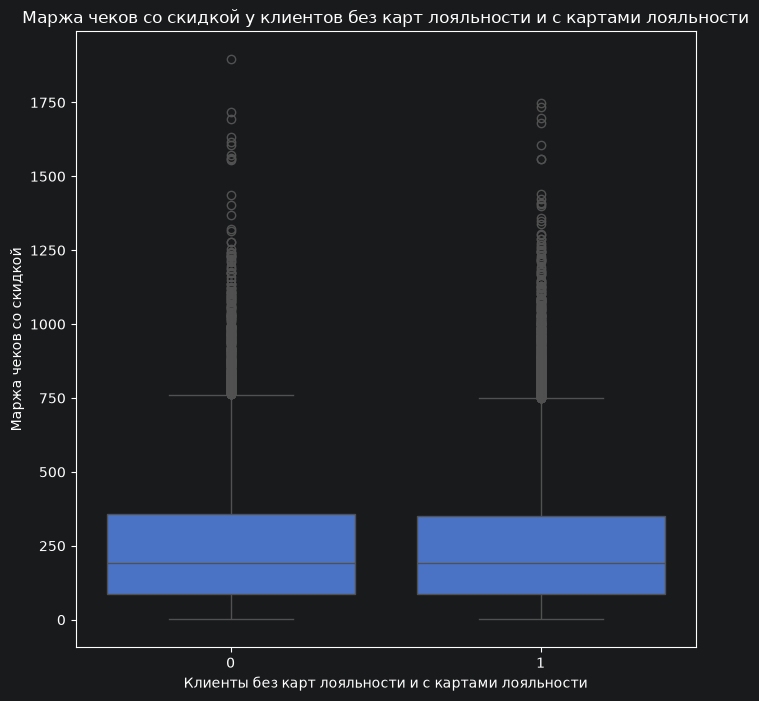

In [26]:
plt.figure(figsize=(8, 8))
(sns.boxplot(x = 'карта_лояльности', y = df_agg['маржа_со_скидкой_руб'], data = df)
    .set(title = 'Маржа чеков со скидкой у клиентов без карт лояльности и с картами лояльности', xlabel = 'Клиенты без карт лояльности и с картами лояльности',
         ylabel = 'Маржа чеков со скидкой'))
plt.show()

**Выводы:**
- медианы находятся примерно на одном уровне;
- высота и межквартильные размахи ящиков практически одинаковы;
- у обеих групп имеется большое количество выбросов.

## Проверка гипотез

### Гипотеза 1. Средние суммы чеков между клиентами с картами лояльности и без карт различаются.

Н0: Средние суммы чеков в обеих группах **равны**.

Н1: Средние суммы чеков в обеих группах **не равны**.

Одной из основных задач программ лояльности является увеличение среднего чека. Поэтому для начала проверим, различаются ли средние суммы чеков между двумя группами клиентов. Выбор двухсторонней альтернативы обусловлен тем, что средние чеки лояльных клиентов могут как падать за счет применения скидок, так и расти за счет увеличения объема покупок.

In [27]:
print('Количество чеков С КАРТАМИ', len(with_card))
print('Количество чеков БЕЗ КАРТ', len(no_card))

Количество чеков С КАРТАМИ 12521
Количество чеков БЕЗ КАРТ 10269


In [28]:
print('Дисперсия чеков С КАРТАМИ', round(np.var(with_card['сумма_строки_со_скидкой'], ddof=1), 2))
print('Дисперсия чеков БЕЗ КАРТ', round(np.var(no_card['сумма_строки_со_скидкой'], ddof=1), 2))

Дисперсия чеков С КАРТАМИ 671188.87
Дисперсия чеков БЕЗ КАРТ 706903.58


Для проверки гипотезы о равенстве средних сумм чеков используем параметрическй тест t-критерий Уэлча.

Требования к применимости теста соблюдены:
1. Выборки независимы (транзакции разных групп покупателей);
2. Несмотря на ненормальное распределение исходных данных (чеков), объем выборок (N1 = 12521, N2 = 10269) позволяет опираться на ЦПТ, утверждающую нормальность распределения выборочных средних;
3. В связи с неравенством объемов выборок и их дисперсий, расчет проводился с поправкой Уэлча (equal_var=False).

In [29]:
statistic, p_value = ttest_ind(with_card['сумма_строки_со_скидкой'], no_card['сумма_строки_со_скидкой'], equal_var=False)
alpha = 0.05

print('p-значение: ', p_value)
if p_value > alpha:
    print('Опровергнуть нулевую гипотезу нельзя')
else:
    print('Принимаем альтернативную гипотезу')

p-значение:  0.011222708871744933
Принимаем альтернативную гипотезу


In [30]:
print('Средний чек клиентов с картами лояльности - {:,.2f} руб.'.format(with_card['сумма_строки_со_скидкой'].mean()))
print('Средний чек клиентов без карт лояльности - {:,.2f} руб.'.format(no_card['сумма_строки_со_скидкой'].mean()))

Средний чек клиентов с картами лояльности - 947.85 руб.
Средний чек клиентов без карт лояльности - 975.91 руб.


По результатам проведенного теста критерий Уэлча подтвердил наличие статистически значимых различий между средними чеками клиентов с картами лояльности и без них на уровне значимости 5%.

Однако для бизнеса эта разница достаточна мала: средний чек лояльных клиентов ниже всего на 3,0% (947.85 руб. против 975.91 руб.). Таким образом, карта лояльности почти не меняет сумму покупки в большую сторону, а скорее немного её снижает за счет начисления скидок.

In [31]:
# Преобразуем данные и приведем их к нормальному распределению
# Для выбора лучшего преобразования сравним коэффициенты асимметрии
def check_skew(data):
    print('Исходные:', data.skew())
    print('log_transform:', np.log(data).skew())
    print('log10_transform:', np.log10(data).skew())
    print('inverse_transform:', (1/data).skew())
    print('sqrt_transform:', np.sqrt(data).skew())
    print('cbrt_transform:', np.cbrt(data).skew())

In [32]:
check_skew(with_card['сумма_строки_со_скидкой'])

Исходные: 1.5415255597441582
log_transform: -0.5409161963104643
log10_transform: -0.5409161963104663
inverse_transform: 2.9855554045866994
sqrt_transform: 0.5004805574755053
cbrt_transform: 0.16098066324669713


In [33]:
check_skew(no_card['сумма_строки_со_скидкой'])

Исходные: 1.4531209621677121
log_transform: -0.5373085989349178
log10_transform: -0.5373085989349172
inverse_transform: 2.8714257564953933
sqrt_transform: 0.46091329973444406
cbrt_transform: 0.1357200336917


Лучшее приближение к нормальности показала трансформация кубическим корнем (np.cbrt()) (коэффициенты асимметрии для данных с картами - 0.16, без карт - 0.14).

In [34]:
# Преобразуем данные и проведем тест
cbrt_transform_with_card = np.cbrt(with_card['сумма_строки_со_скидкой'])
cbrt_transform_no_card = np.cbrt(no_card['сумма_строки_со_скидкой'])

# Проведем повторный параметрический тест t-критерий Уэлча
statistic, p_value = ttest_ind(cbrt_transform_with_card, cbrt_transform_no_card, equal_var=False)
alpha = 0.05

print('p-значение: ', p_value)
if p_value > alpha:
    print('Опровергнуть нулевую гипотезу нельзя')
else:
    print('Принимаем альтернативную гипотезу')

p-значение:  0.04533231013324853
Принимаем альтернативную гипотезу


Повторный тест t-критерий Уэлча на данных, преобразованных кубическим корнем, так же подтвердил статистическую значимость различий в средних значениях на уровне p-value < 0.05.

### Гипотеза 2. Распределения сумм чеков между клиентами с картами лояльности и без карт различаются.

Н0: Распределения сумм чеков в обеих группах **одинаковы**.

Н1: Распределения сумм чеков в обеих группах **различаются**.

В качестве дополнения к t-тесту Уэлча проверим сдвиг распределений с помощью непараметрического теста Манна-Уитни, который оценивает ранги и устойчив к экстремальным выбросам (аномально большим чекам). Это позволит проверить изменение без искажений со стороны крупных случайных покупок.

In [35]:
statistic, p_value = mannwhitneyu(with_card['сумма_строки_со_скидкой'], no_card['сумма_строки_со_скидкой'], alternative='two-sided')
alpha = 0.05

print('p-значение: ', p_value)
if p_value > alpha:
    print('Опровергнуть нулевую гипотезу нельзя')
else:
    print('Принимаем альтернативную гипотезу')

p-значение:  0.04595560191671414
Принимаем альтернативную гипотезу


In [36]:
print('Медианный чек клиентов с картами лояльности - {:,.2f} руб.'.format(with_card['сумма_строки_со_скидкой'].median()))
print('Медианный чек клиентов без карт лояльности - {:,.2f} руб.'.format(no_card['сумма_строки_со_скидкой'].median()))

Медианный чек клиентов с картами лояльности - 721.24 руб.
Медианный чек клиентов без карт лояльности - 745.78 руб.


По результатам проведенного теста критерий Манна-Уитни подтвердил наличие статистически значимых различий между чеками клиентов с картами лояльности и без них на уровне значимости 5%.

Однако, как и в случае с результатами теста Уэлча, разница на самом деле достаточно маленькая: медианный чек лояльных клиентов ниже всего на 3.4% (721.24 руб. против 745.78 руб.).
Следовательно, клиенты с картами лояльности приносят меньше выручки за счет применения скидок.

### Гипотеза 3. Средняя маржа чеков между клиентами с картами лояльности и без карт различаются.

Н0: Средняя маржа чеков в обеих группах **равны**.

Н1: Средняя маржа чеков в обеих группах **не равны**.

Средний чек показывает выручку, но не учитывает затратную часть (в данном случае - себестоимость товаров). Для полной оценки влияния программы лояльности на чистый доход необходимо проверить гипотезу о маржинальной прибыли. Выбор двухсторонней альтернативы обусловлен тем, что маржа может измениться в любую сторону: она может как вырасти за счет увеличения объема покупок, так и упасть из-за предоставления скидок по картам лояльности.

In [37]:
print('Дисперсия чеков С КАРТАМИ:', round(np.var(with_card['маржа_со_скидкой_руб'], ddof=1), 2))
print('Дисперсия чеков БЕЗ КАРТ', round(np.var(no_card['маржа_со_скидкой_руб'], ddof=1), 2))

Дисперсия чеков С КАРТАМИ: 43028.35
Дисперсия чеков БЕЗ КАРТ 54348.93


Для проверки гипотезы о равенстве средних сумм чеков используем параметрическй тест t-критерий Уэлча.

Требования к применимости теста соблюдены:
1. Выборки независимы (транзакции разных групп покупателей);
2. Несмотря на ненормальное распределение исходных данных (чеков), объем выборок (N1 = 12521, N2 = 10269) позволяет опираться на ЦПТ, утверждающую нормальность распределения выборочных средних;
3. В связи с неравенством объемов выборок и их дисперсий, расчет проводился с поправкой Уэлча (equal_var=False).

In [38]:
statistic, p_value = ttest_ind(with_card['маржа_со_скидкой_руб'], no_card['маржа_со_скидкой_руб'], equal_var=False)
alpha = 0.05

print('p-значение: ', p_value)
if p_value > alpha:
    print('Опровергнуть нулевую гипотезу нельзя')
else:
    print('Принимаем альтернативную гипотезу')

p-значение:  9.971226046396588e-29
Принимаем альтернативную гипотезу


In [39]:
print('Средняя маржа чека клиентов с картами лояльности - {:,.2f} руб.'.format(with_card['маржа_со_скидкой_руб'].mean()))
print('Средняя маржа чека клиентов без карт лояльности - {:,.2f} руб.'.format(no_card['маржа_со_скидкой_руб'].mean()))
print('Медианная маржа чека клиентов с картами лояльности - {:,.2f} руб.'.format(with_card['маржа_со_скидкой_руб'].median()))
print('Медианная маржа чека клиентов без карт лояльности - {:,.2f} руб.'.format(no_card['маржа_со_скидкой_руб'].median()))

Средняя маржа чека клиентов с картами лояльности - 237.91 руб.
Средняя маржа чека клиентов без карт лояльности - 270.81 руб.
Медианная маржа чека клиентов с картами лояльности - 181.21 руб.
Медианная маржа чека клиентов без карт лояльности - 207.26 руб.


P-значение критерия Уэлча крайне мало, что дает основание отвергнуть нулевую гипотезу. Случайность полученных результатов маловероятна.

Средняя и медианная маржа чеков лояльных клиентов значительно ниже - на 13.8% и 14.4% соответственно. Следовательно, начисление скидок не только снижает общую сумму чека, но и существенно урезает его чистую маржинальность.

Результаты проведенных тестов подтвердили необходимость пересмотра механики начисления скидок на отдельные категории товаров.

### Гипотеза 4. Изначальная маржинальность чеков (до применения скидок) у клиентов с картами лояльности и без карт различается.

Н0: Распределения базовой маржинальности чеков (в %) в обеих группах **идентичны** (изначальная доходность чеков **равна**)

Н1: Распределения базовой маржинальности чеков (в %) в обеих группах **различаются** (доходность чеков **не равна**)

Предыдущий тест показал, что маржинальность лояльных клиентов значительно ниже, чем у покупателей без карт. Необходимо проверить, связано ли это с тем, что держатели карт лояльности изначально выбирают более дешевые или низкомаржинальные категории товаров. Выбор двухсторонней альтернативы обусловлен тем, что базовая маржинальность групп может отличаться в любую сторону: лояльные клиенты могут как целенаправленно покупать товары с низкой наценкой, так и, наоборот, выбирать более дорогие и прибыльные.

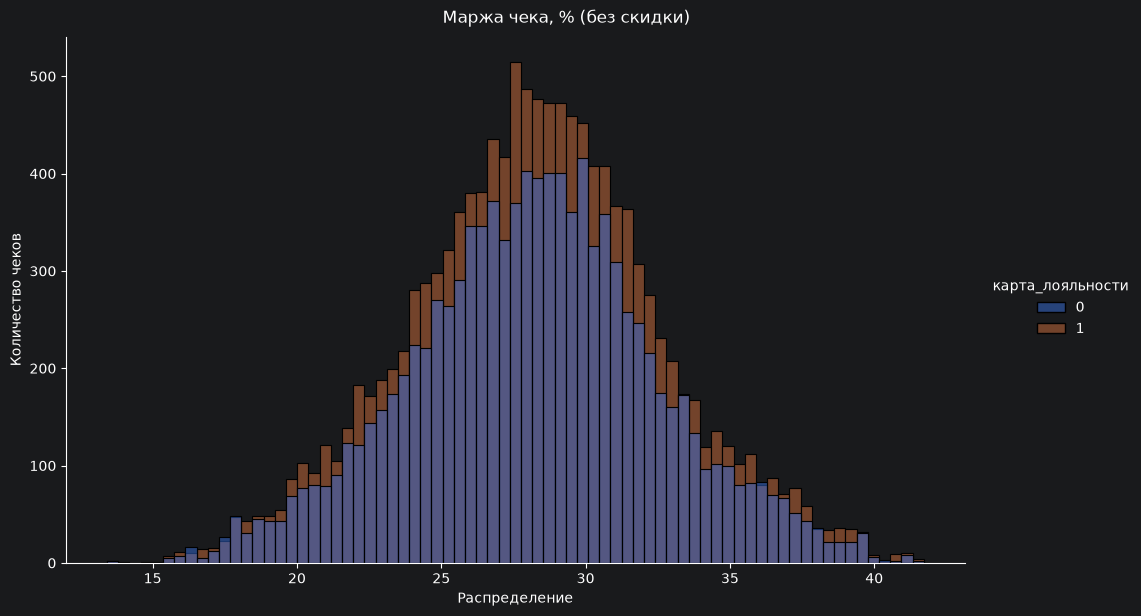

In [40]:
# Посмотрим на распределение выборок
g = sns.displot(df, x=df_agg['маржа_чека_без_скидки_проц'], hue='карта_лояльности', kind='hist', height=6, aspect=1.66)
g.set_axis_labels('Распределение', 'Количество чеков')
g.figure.suptitle('Маржа чека, % (без скидки)', y=1.02)
plt.show()

In [41]:
print('Дисперсия чеков С КАРТАМИ', round(np.var(with_card['маржа_чека_без_скидки_проц'], ddof=1), 2))
print('Дисперсия чеков БЕЗ КАРТ', round(np.var(no_card['маржа_чека_без_скидки_проц'], ddof=1), 2))

Дисперсия чеков С КАРТАМИ 18.69
Дисперсия чеков БЕЗ КАРТ 19.0


Визуальный анализ гистограммы показал, что базовая маржинальность чеков (в % до скидки) имеет симметричную колоколообразную форму и подчиняется нормальному закону распределения.

Расчеты подтвердили близость дисперсий в обеих группах (18.69 у клиентов с картами против 19.0 у клиентов без карт).

Учитывая нормальность данных, большой объем выборок и незначительное различие дисперсий, для проверки гипотезы применим параметрический тест t-критерий Уэлча

In [42]:
statistic, p_value = ttest_ind(with_card['маржа_чека_без_скидки_проц'], no_card['маржа_чека_без_скидки_проц'], equal_var=False)
alpha = 0.05

print('p-значение: ', p_value)
if p_value > alpha:
    print('Опровергнуть нулевую гипотезу нельзя')
else:
    print('Принимаем альтернативную гипотезу')

p-значение:  0.7898369017630402
Опровергнуть нулевую гипотезу нельзя


In [43]:
print('Средняя маржинальность чека С КАРТАМИ (до скидки) - {:,.2f} %.'.format(with_card['маржа_чека_без_скидки_проц'].mean()))
print('Средняя маржинальность чека БЕЗ КАРТ (до скидки) - {:,.2f} %.'.format(no_card['маржа_чека_без_скидки_проц'].mean()))
print('Медианная маржинальность чека С КАРТАМИ (до скидки) - {:,.2f} %.'.format(with_card['маржа_чека_без_скидки_проц'].median()))
print('Медианная маржинальность чека БЕЗ КАРТ (до скидки) - {:,.2f} %.'.format(no_card['маржа_чека_без_скидки_проц'].median()))

Средняя маржинальность чека С КАРТАМИ (до скидки) - 28.23 %.
Средняя маржинальность чека БЕЗ КАРТ (до скидки) - 28.21 %.
Медианная маржинальность чека С КАРТАМИ (до скидки) - 28.29 %.
Медианная маржинальность чека БЕЗ КАРТ (до скидки) - 28.24 %.


Значение p-value намного больше, чем 0.05, т.е. никаких статистически значимых различий в выборе товаров нет. Разница в сотые доли процента в средней и медианной базовой маржинальности чеков лояльных клиентов и клиентов без карт - это случайность.

Следовательно, опровергается предположение о том, что держатели карт лояльности изначально выбирают более дешевые или низкомаржинальные категории товаров. Лояльные и обычные клиенты покупают одинаковые по своей доходности и структуре категории товаров.

Таким образом, падение чистой маржи чека на 14.4% вызвано неэффективной механикой предоставления скидок лояльным клиентам, а не изменением покупательского поведения.

### Гипотеза 5. Существует взаимосвязь между категорией приобретаемого товара и размером предоставляемой по карте скидки (5%, 10%, 15%).

Н0: Категория товара и размер скидки независимы друг от друга (распределение скидок 5%, 10% и 15% одинаковы для всех категорий товаров)

Н1: Категория товара и размер скидки статистически взаимосвязаны (в определенных категориях товаров наблюдается явный перекос в сторону конкретного размера скидки).

Предыдущий тест показал, что лояльные и обычные клиенты выбирают одинаковые по своей базовой доходности категории товаров. В связи с этим необходимо проверить другое предположение: возможно, лояльные клиенты целенаправленно выбирают товары с максимальным размером скидки.

Для оценки взаимосвязи между категорией приобретаемого товара и величиной предоставляемой скидки применен непараметрический тест хи-квадрат Пирсона.
Все требования к применимости критерия соблюдены:
1. Оба признака являются категориальными;
2. Наблюдения независимы;
3. Количество наблюдений больше 20.

In [44]:
df_with_card = df[df['карта_лояльности'] == 1]
contingency_table = pd.crosstab(
    df_with_card['категория_товара'],
    df_with_card['скидка_процент']
)
contingency_table

скидка_процент,0,5,10,15
категория_товара,,,,
Алкоголь,2158,405,382,384
Бакалея,2063,372,399,392
Готовая еда,2029,382,372,383
Детское питание,1977,370,374,401
Замороженные продукты,2097,380,373,378
Молочка,2090,365,360,372
Мясо и птица,2060,361,379,346
Напитки,2200,386,375,428
Непрод. товары,1955,385,364,378


In [45]:
chi2, p_value, dof, expected = chi2_contingency(contingency_table)
alpha = 0.05

print('p-значение: ', p_value)
if p_value > alpha:
    print('Опровергнуть нулевую гипотезу нельзя')
else:
    print('Принимаем альтернативную гипотезу')

p-значение:  0.827079790777243
Опровергнуть нулевую гипотезу нельзя


P-значение намного больше критического порога 0.05, т.е. никакой статистически значимой взаимосвязи между категорией товара и размером скидки (5%, 10%, 15%) нет. Все обнаруженные отклонения в данных — это чистая случайность.

Лояльные клиенты распределяют свои покупки по категориям равномерно, независимо от того, какая скидка (5%, 10% или 15%) установлена на товар. Поведение покупателей однородно, они не выбирают целенаправленно товары с максимальной скидкой

Таким образом, еще раз подтверждается неэффективность правил скидок в программе лояльности - скидки распределятся на все подряд без привязки к реальности доходности категорий товаров.

### Гипотеза 6. Количество товаров в чеке (размер корзины) у клиентов с картами лояльности и без карт различается.

Н0: Распределения количества товаров в чеке в обеих группах **идентичны** (размер корзины в группах **равен**)

Н1: Распределения количества товаров в чеке в обеих группах **различаются** (размер корзины в группах **не равен**)

Все предыдущие тесты показали, что программа лояльности снижает выручку и чистый доход с "лояльных" чеков. Необходимо проверить, увеличивает ли она хотя бы размер корзины постоянных клиентов. Выбрана двухсторонняя альтернатива, потому что размер корзины может измениться в любую сторону. Вместо роста покупок программа лояльности может сработать наоборот - клиенты станут заходить чаще, но брать меньше товаров за раз.

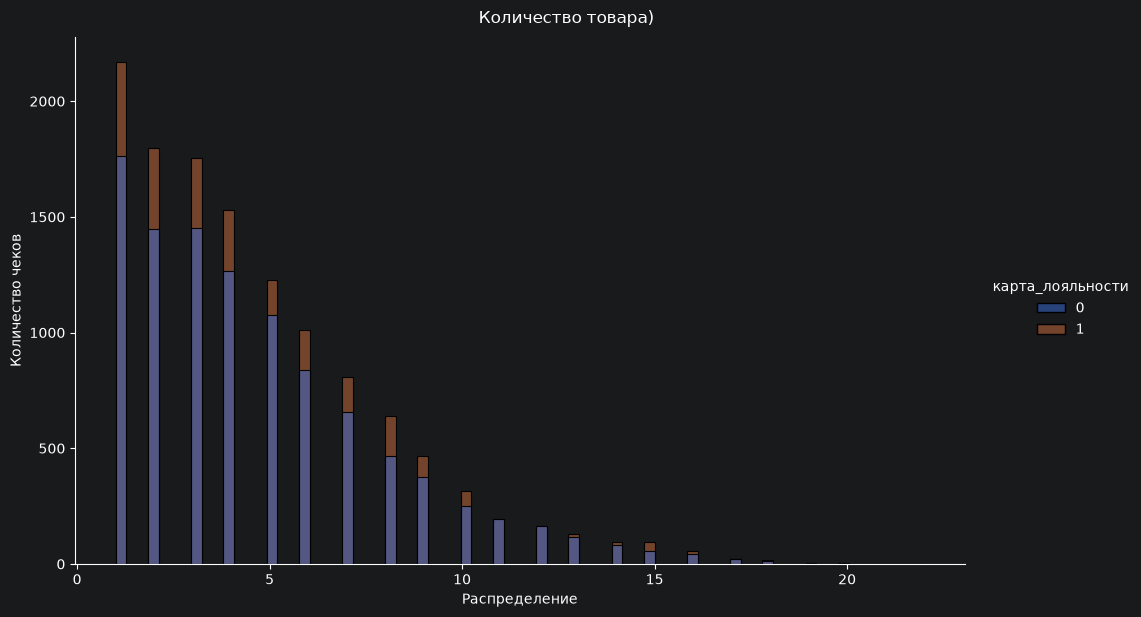

In [46]:
# Посмотрим на распределение выборок
g = sns.displot(df, x=df_agg['количество_товара'], hue='карта_лояльности', kind='hist', height=6, aspect=1.66)
g.set_axis_labels('Распределение', 'Количество чеков')
g.figure.suptitle('Количество товара)', y=1.02)
plt.show()

Для проверки гипотезы о равенстве распределений сумм чеков используем непараметрическй тест u-критерий Манна-Уитни, т.к. метрика "количество товаров" представляет собой дискретную величину, распределение которой обладает сильной асимметрией. Тест устойчив к скошенным распределениям и позволяет корректно определить наличие сдвига в размерах покупательских корзин между двумя группами клиентов.

In [47]:
statistic, p_value = mannwhitneyu(with_card['количество_товара'], no_card['количество_товара'], alternative='two-sided')
alpha = 0.05

print('p-значение: ', p_value)
if p_value > alpha:
    print('Опровергнуть нулевую гипотезу нельзя')
else:
    print('Принимаем альтернативную гипотезу')

p-значение:  0.3125105187786401
Опровергнуть нулевую гипотезу нельзя


In [48]:
print('Среднее число товаров в чеке С КАРТАМИ - {:,.2f} шт.'.format(with_card['количество_товара'].mean()))
print('Среднее число товаров в чеке БЕЗ КАРТ - {:,.2f} шт.'.format(no_card['количество_товара'].mean()))
print('Медианное число товаров в чеке С КАРТАМИ - {:,.2f} шт.'.format(with_card['количество_товара'].median()))
print('Медианное число товаров в чеке БЕЗ КАРТ - {:,.2f} шт.'.format(no_card['количество_товара'].median()))

Среднее число товаров в чеке С КАРТАМИ - 4.65 шт.
Среднее число товаров в чеке БЕЗ КАРТ - 4.61 шт.
Медианное число товаров в чеке С КАРТАМИ - 4.00 шт.
Медианное число товаров в чеке БЕЗ КАРТ - 4.00 шт.


Полученное p-значение значительно превышает критический порог 0.05, что не дает оснований отвергнуть нулевую гипотезу. Различия в количестве товаров в чеке между группами статистически не значимы и абсолютно случайны.
Бизнес-метрики также подтверждают этот вывод: медианный размер корзины в обеих группах идентичен и равен 4.00 шт. товаров на чек, а разница средних значений крайне мала - 4.65 шт. с картой против 4.61 шт. без карты.

Таким образом, программа лояльности никак не стимулирует клиентов увеличивать объем корзины и покупать больше штук товара. Покупатель с картой лояльности берет столько же товаров, сколько и клиенты без карты.

## Общий вывод и рекомендации

На основе статистического анализа выборки из более чем 22 000 чеков установлено, что текущая программа лояльности демонстрирует экономическую неэффективность и снижает потенциальную прибыль компании.

Результаты статистического анализа:
- падение среднего чека: вместо роста показателей, средний чек клиентов с картами лояльности оказался ниже и составил 947.85 руб. (медиана 721.24 руб.) против 975.91 руб. (медиана 745.78 руб.) у клиентов без карт.
- снижение чистой прибыли: из-за нерациональной механики применения скидок компания недополучает чистую прибыль с лояльных клиентов. Медианная маржа с одного чека с картой лояльности составляет 181.21 руб. против 207.26 руб. без карты, что на 14.4% выше доходности чека постоянного клиента.
- отсутствие стимуляции спроса: наличие карты лояльности не увеличивает объем покупок. Типичный размер корзины в обеих группах идентичен и составляет 4 товара (в среднем 4.65 шт. с картами против 4.61 шт. без карт).
- одинаковое покупательское поведение: анализ изначальной маржинальности покупательских корзин (до применения скидок) показал, что клиенты обеих групп изначально выбирают товары с абсолютно одинаковой доходностью для компании - медианная маржинальность составляет 28.29% с картами и 28.24% без карт.

Таким образом, необходимо полностью пересмотреть стратегию программы лояльности. В качестве альтернатив можно рассмотреть:
- переход на бонусную (накопительную) систему вместо прямых скидок. Это позволит возвращать клиента за повторными покупками;
- введение минимального порога чека для активации скидок или списания бонусов, что простимулирует клиентов увеличивать объем корзины;
- дифференциацию условий: размер скидок или процент начисления бонусов должен динамически меняться в зависимости от маржинальности конкретной категории товара (меньше скидка на низкомаржинальные товары, больше - на высокомаржинальные).